# Выживаемость: Каплан–Мейер и модель Кокса

Задача: понять, как долго клиенты сохраняют подписку после первой оплаты и какие признаки связаны с более ранним уходом.
Анализ выживаемости подходит для этого, потому что наблюдения неполны: клиент, начавший платить незадолго до марта 2017,
ещё не ушёл, но и его будущее неизвестно. Такие наблюдения (цензурированные) не отбрасываются, а учитываются до момента,
пока клиент находился под наблюдением.

**Определения.**
- Единица анализа: клиент из когорт первой платной подписки с 2015-07 по 2016-12 (те же когорты, что в LTV).
- `t`: число подряд идущих активных месяцев, начиная с месяца первой платной подписки (месяц 0). Это строгое удержание, как в `02_cohorts`.
- `event`: равно 1, если после этих месяцев наступил месяц без действующей подписки и он попал в период наблюдений; равно 0, если наблюдения закончились (март 2017) раньше, чем клиент ушёл.
- Функция выживания S(a) это доля клиентов, у которых подписка действовала непрерывно в месяцах 0..a. Это то же событие, что `t > a`,
  поэтому S(a) прямо сопоставима с кривой строгого удержания из `02_cohorts`.

**План ноутбука.**
1. Выбрать клиентов (выборка по хешу `msno`, доля `SAMPLE_SHARE`) и собрать таблицу: по одной строке на клиента.
2. Оценить кривую выживаемости методом Каплана–Мейера для всех клиентов и по сегментам.
3. Оценить модель Кокса, чтобы сравнить влияние признаков при прочих равных, и проверить её допущения.
4. Сопоставить результаты с исторической LTV.

Редкие категории (меньше 1000 клиентов, порог пересчитан на долю выборки) объединяются в «other», как в `01_rare_segments`.
Тариф, способ оплаты и автопродление берутся из первой платной транзакции, способ регистрации и наличие профиля из `members`.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import proportional_hazard_test

P = "/workspace/data/processed/"
LAST_MONTH = "2017-03-01"  # последний месяц наблюдений
C_FROM, C_TO = "2015-07-01", "2016-12-01"
SAMPLE_SHARE = 15  # процент клиентов в выборке
RARE_MIN = 1000 * SAMPLE_SHARE / 100  # порог редкой категории в выборке
INK, BLUE, ORANGE, GREEN, GRAY = "#2b2f36", "#0072B2", "#E69F00", "#009E73", "#8a8f98"
PALETTE = [BLUE, ORANGE, GREEN, GRAY, "#CC79A7", "#56B4E9"]

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

con = duckdb.connect()
con.execute(
    "SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false; "
    "SET temp_directory='/workspace/data/_duckdb_tmp'"
)
for name, file in [("tr", "transactions"), ("act", "active_months"), ("anc", "user_anchors"), ("mem", "members")]:
    con.execute(f'''
        CREATE VIEW {name} AS
        SELECT *
        FROM '{P}{file}.parquet'
    ''')

## 1. Данные: таблица клиентов
SQL-запрос собирает таблицу `surv`, где каждая строка это один клиент выборки. Столбцы:
- `cohort`: месяц первой платной подписки;
- `t`: число подряд идущих активных месяцев с месяца когорты (считается по таблице активных месяцев: ищется первый пропуск);
- `event`: 1, если месяц `cohort + t` (первый без подписки) наблюдается, иначе 0 (клиент цензурирован);
- `plan_days`, `method`, `auto_renew`: длина тарифа, способ оплаты и автопродление первой платной транзакции;
- `via`: способ регистрации (`no_profile`, если клиента нет в `members`);
- `has_profile`: 1, если клиент есть в `members`.

In [2]:
surv = con.sql(f'''
    WITH coh AS (
        SELECT
            msno,
            first_paid_month AS cohort,
            reg_month
        FROM anc
        WHERE first_paid_month BETWEEN DATE '{C_FROM}' AND DATE '{C_TO}'
            AND hash(msno) % 100 < {SAMPLE_SHARE}
    ),
    first_tx AS (
        SELECT
            msno,
            payment_plan_days,
            payment_method_id,
            is_auto_renew
        FROM (
            SELECT
                tr.msno,
                tr.payment_plan_days,
                tr.payment_method_id,
                tr.is_auto_renew,
                row_number() OVER (
                    PARTITION BY tr.msno
                    ORDER BY tr.transaction_date, tr.payment_plan_days DESC, tr.payment_method_id
                ) AS rn
            FROM tr
            JOIN coh USING (msno)
            WHERE tr.is_cancel = 0
                AND tr.actual_amount_paid > 0
        )
        WHERE rn = 1
    ),
    ages AS (
        SELECT
            coh.msno,
            date_diff('month', coh.cohort, act.month) AS age,
            row_number() OVER (PARTITION BY coh.msno ORDER BY act.month) AS rn
        FROM coh
        JOIN act USING (msno)
        WHERE act.month >= coh.cohort
    ),
    run AS (
        SELECT
            msno,
            count(*) FILTER (WHERE age = rn - 1) AS t
        FROM ages
        GROUP BY msno
    )
    SELECT
        coh.msno,
        coh.cohort,
        coalesce(run.t, 0) AS t,
        (coh.cohort + to_months(coalesce(run.t, 0)::INT) <= DATE '{LAST_MONTH}')::INT AS event,
        first_tx.payment_plan_days AS plan_days,
        first_tx.payment_method_id AS method,
        first_tx.is_auto_renew AS auto_renew,
        coalesce(mem.registered_via::VARCHAR, 'no_profile') AS via,
        (coh.reg_month IS NOT NULL)::INT AS has_profile
    FROM coh
    JOIN first_tx USING (msno)
    LEFT JOIN run USING (msno)
    LEFT JOIN mem USING (msno)
''').df()

print("клиентов в выборке:", len(surv))
print("событие наступило у", round(100 * surv.event.mean(), 1), "% клиентов, цензурировано", round(100 * (1 - surv.event.mean()), 1), "%")
print("клиентов с t = 0 (подписка не действовала даже в месяце когорты):", int((surv.t == 0).sum()))
surv.t.describe().round(2).to_frame("t").T

клиентов в выборке: 131381
событие наступило у 35.6 % клиентов, цензурировано 64.4 %
клиентов с t = 0 (подписка не действовала даже в месяце когорты): 0


,count,mean,std,min,25%,50%,75%,max
t,131381.0,10.02,6.01,1.0,4.0,9.0,15.0,21.0


## 2. Подготовка признаков
Из таблицы `surv` строится рабочая таблица `d`: в неё входят клиенты с `t > 0` (клиент без единого активного месяца не имеет интервала
до события), а к исходным столбцам добавляются:
- `plan`: группа длины тарифа (до 29 дней, 30–31 день, 32–179 дней, 180 дней и больше);
- `method_g`, `via_g`: способ оплаты и способ регистрации, где редкие значения объединены в «other» (функция `group_rare`);
- подписи для графиков (`profile`, `autorenew_label`).

Функция `group_rare` объединяет значения с числом клиентов меньше порога. Если сама категория «other» получается меньше порога,
к ней добавляются наименее частые из оставшихся значений, пока порог не будет достигнут: иначе оценка по крошечной категории ненадёжна.

In [3]:
def group_rare(s: pd.Series, min_n: float = RARE_MIN) -> pd.Series:
    '''Объединяет редкие значения категориального признака в «other».

    Args:
        s (pd.Series): значения признака.
        min_n (float): минимальное число клиентов, чтобы значение осталось отдельным.

    Returns:
        pd.Series: значения в виде строк, редкие заменены на «other»; если «other» меньше порога,
            в неё добавляются наименее частые из оставшихся значений.
    '''
    s = s.astype(str)
    counts = s.value_counts()
    rare = list(counts[counts < min_n].index)
    kept = [v for v in counts.index if v not in rare]
    while rare and counts[rare].sum() < min_n and kept:
        rare.append(kept.pop())  # kept отсортирован по убыванию частоты, берём самое редкое
    return s.where(~s.isin(rare), "other")


def plan_group(days: int) -> str:
    '''Относит длину тарифа в днях к группе.

    Args:
        days (int): длина тарифа в днях.

    Returns:
        str: название группы.
    '''
    if days < 30:
        return "до 29 дней"
    if days <= 31:
        return "30-31 день"
    if days < 180:
        return "32-179 дней"
    return "180 дней и больше"


d = surv[surv.t > 0].copy()
d["plan"] = d.plan_days.map(plan_group)
d["method_g"] = group_rare(d.method)
d["via_g"] = group_rare(d.via)
d["auto_renew"] = d.auto_renew.astype(int)
d["profile"] = d.has_profile.map({1: "есть профиль", 0: "нет профиля"})
d["autorenew_label"] = d.auto_renew.map({1: "автопродление", 0: "без автопродления"})
print("клиентов в анализе:", len(d))
for c in ["plan", "via_g", "method_g"]:
    print(d[c].value_counts().to_string(), end="\n\n")

клиентов в анализе: 131381
plan
30-31 день           114054
180 дней и больше     14063
32-179 дней            2865
до 29 дней              399

via_g
7             50102
9             26707
no_profile    19470
3             18758
4             15983
other           361

method_g
41       66940
38       26309
36       10352
32        8223
40        3796
29        3291
39        2416
30        2185
20        1694
37        1658
28        1424
22        1170
other      583
13         300
33         268
12         259
27         183
31         167
16         163



## 3. Кривая выживаемости для всех клиентов
Метод Каплана–Мейера для каждого месяца, в котором кто-то ушёл, считает долю продолживших среди клиентов, остававшихся под наблюдением
к этому месяцу (ушедшие и цензурированные раньше в знаменатель не входят). S(a) это произведение таких долей по всем месяцам до a.
Доверительный интервал 95% (формула Гринвуда, преобразование через логарифм) показывает неопределённость оценки из-за конечного размера выборки.

В таблице под графиком: S(a) и границы интервала для месяцев 1, 3, 6, 12 и 18.
Сверка: в `02_cohorts` для когорт 2015-07 .. 2016-03 к 12-му месяцу строго удержано 64,2%. Здесь набор когорт шире (до 2016-12)
и учитывается цензурирование, поэтому совпадение приблизительное.

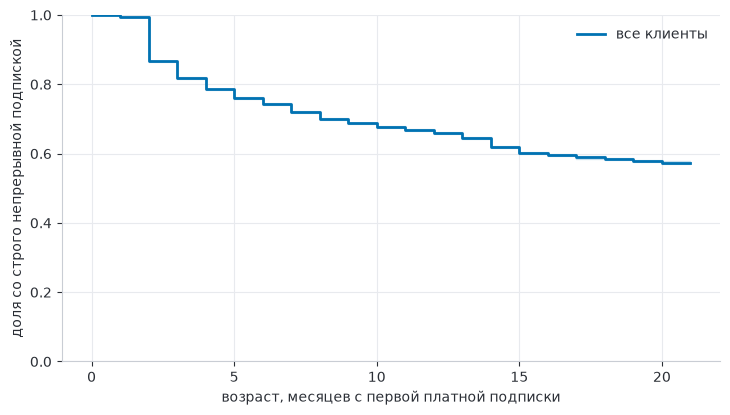

,S(a),нижняя 95%,верхняя 95%
1,0.996,0.995,0.996
3,0.819,0.817,0.821
6,0.743,0.741,0.746
12,0.660,0.657,0.663
18,0.584,0.580,0.587


In [4]:
kmf = KaplanMeierFitter()
kmf.fit(d.t, d.event, label="все клиенты")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
kmf.plot_survival_function(ax=ax, color=BLUE, lw=2, ci_alpha=0.15)
ax.set_xlabel("возраст, месяцев с первой платной подписки")
ax.set_ylabel("доля со строго непрерывной подпиской")
ax.set_ylim(0, 1)
ax.legend(frameon=False)
plt.show()

ages = [1, 3, 6, 12, 18]
sf = kmf.survival_function_["все клиенты"].reindex(ages)
ci = kmf.confidence_interval_.reindex(ages)
pd.DataFrame({"S(a)": sf.round(3), "нижняя 95%": ci.iloc[:, 0].round(3), "верхняя 95%": ci.iloc[:, 1].round(3)})

## 4. Кривые по сегментам
Функция `km_by` для выбранного признака строит кривую Каплана–Мейера для каждого значения и возвращает таблицу.
Строки таблицы это сегменты, столбцы это показатели:
- `клиентов`: размер сегмента;
- `S(3)`, `S(12)`: доля клиентов сегмента с непрерывной подпиской до 3-го и 12-го месяца;
- `активных месяцев из первых 12`: сумма S(a) по a = 0..11, ожидаемое число месяцев с действующей подпиской в первый год
  (ограниченное среднее время жизни).

Различия между сегментами это наблюдения, а не причинные эффекты: тариф и автопродление выбирают не случайные клиенты.
У тарифов от 180 дней предоплата сама удерживает клиента в «активных» до конца оплаченного срока.

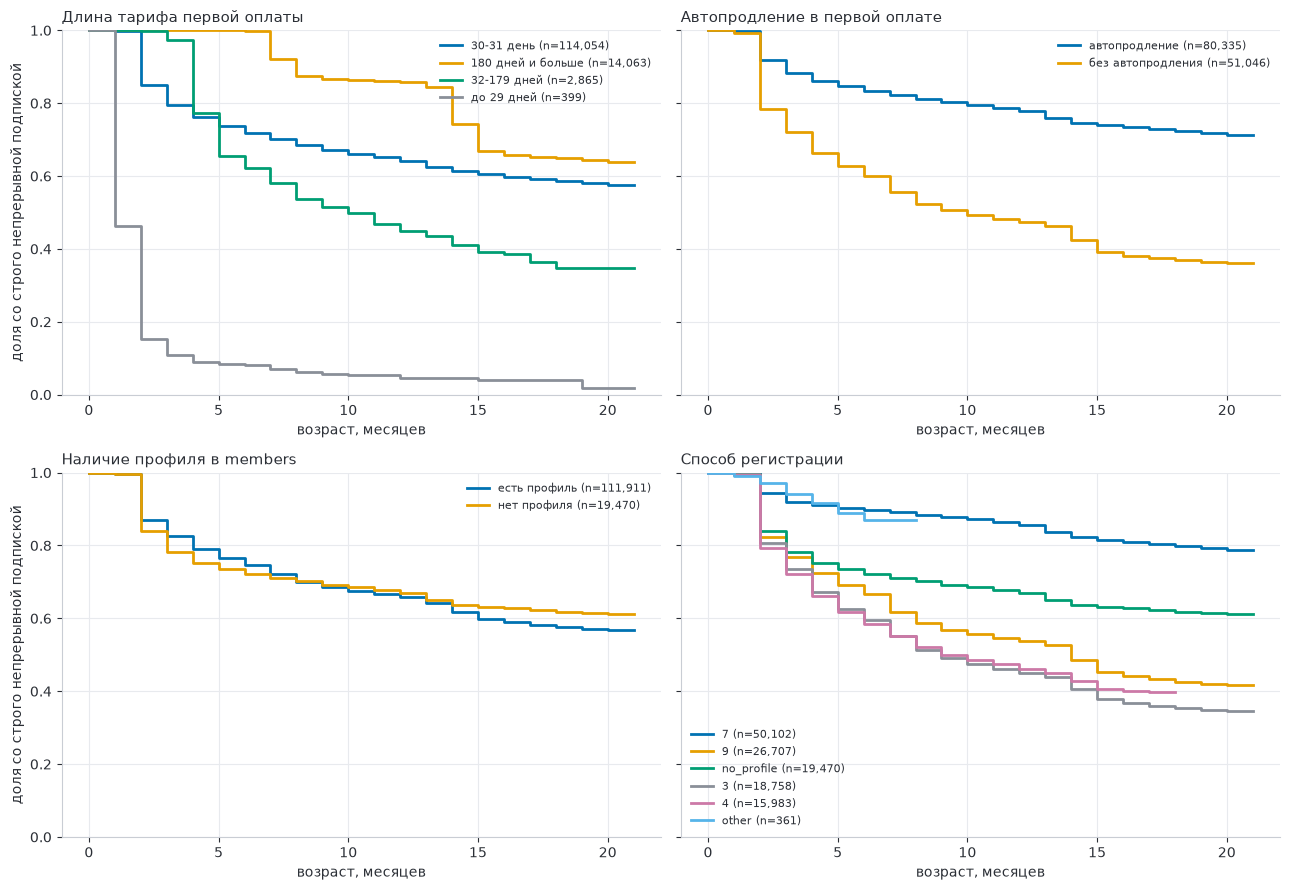

In [5]:
def surv_at(s: pd.Series, age: int) -> float:
    '''Возвращает значение ступенчатой функции выживания в возрасте `age`.

    Args:
        s (pd.Series): функция выживания, индекс это возраст.
        age (int): возраст в месяцах.

    Returns:
        float: значение S в возрасте `age`. Функция выживания постоянна между месяцами, в которые кто-то уходит,
            поэтому берётся значение в последнем таком месяце, не позже `age`.
    '''
    return float(s[s.index <= age].iloc[-1])


def km_by(col: str, ax: plt.Axes, title: str, order: list | None = None) -> pd.DataFrame:
    '''Строит кривые Каплана–Мейера по значениям признака и сводную таблицу.

    Args:
        col (str): столбец сегмента в `d`.
        ax (plt.Axes): оси для графика.
        title (str): заголовок графика.
        order (list | None): порядок значений; по умолчанию по убыванию размера.

    Returns:
        pd.DataFrame: по сегменту: клиентов, S(3), S(12), активных месяцев из первых 12.
    '''
    values = order or list(d[col].value_counts().index)
    rows = {}
    for i, v in enumerate(values):
        g = d[d[col] == v]
        k = KaplanMeierFitter().fit(g.t, g.event)
        k.plot_survival_function(ax=ax, ci_show=False, color=PALETTE[i % len(PALETTE)], lw=2, label=f"{v} (n={len(g):,})")
        s = k.survival_function_.iloc[:, 0]
        rows[v] = {
            "клиентов": len(g),
            "S(3)": round(surv_at(s, 3), 3),
            "S(12)": round(surv_at(s, 12), 3),
            "активных месяцев из первых 12": round(sum(surv_at(s, a) for a in range(12)), 2),
        }
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("возраст, месяцев")
    ax.set_ylim(0, 1)
    ax.legend(frameon=False, fontsize=8)
    return pd.DataFrame(rows).T


fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
tables = {
    "Длина тарифа первой оплаты": km_by("plan", axes[0, 0], "Длина тарифа первой оплаты"),
    "Автопродление": km_by("autorenew_label", axes[0, 1], "Автопродление в первой оплате"),
    "Профиль": km_by("profile", axes[1, 0], "Наличие профиля в members"),
    "Способ регистрации": km_by("via_g", axes[1, 1], "Способ регистрации"),
}
axes[0, 0].set_ylabel("доля со строго непрерывной подпиской")
axes[1, 0].set_ylabel("доля со строго непрерывной подпиской")
plt.tight_layout()
plt.show()

In [6]:
for name, t in tables.items():
    print(name)
    print(t.to_string(), end="\n\n")

Длина тарифа первой оплаты
                   клиентов   S(3)  S(12)  активных месяцев из первых 12
30-31 день         114054.0  0.795  0.642                           9.23
180 дней и больше   14063.0  1.000  0.859                          11.39
32-179 дней          2865.0  0.975  0.450                           8.62
до 29 дней            399.0  0.108  0.047                           2.28

Автопродление
                   клиентов   S(3)  S(12)  активных месяцев из первых 12
автопродление       80335.0  0.882  0.779                          10.36
без автопродления   51046.0  0.720  0.474                           7.95

Профиль
              клиентов   S(3)  S(12)  активных месяцев из первых 12
есть профиль  111911.0  0.825  0.658                           9.44
нет профиля    19470.0  0.783  0.669                           9.30

Способ регистрации
            клиентов   S(3)  S(12)  активных месяцев из первых 12
7            50102.0  0.920  0.858                          10.96
9        

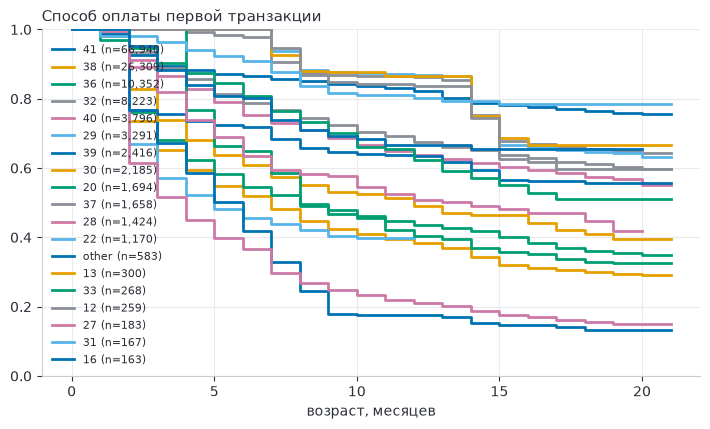

       клиентов   S(3)  S(12)  активных месяцев из первых 12
41      66940.0  0.896  0.822                          10.66
38      26309.0  0.653  0.384                           7.20
36      10352.0  0.682  0.436                           7.60
32       8223.0  1.000  0.864                          11.33
40       3796.0  0.866  0.638                           9.59
29       3291.0  0.571  0.397                           6.75
39       2416.0  0.673  0.175                           6.05
30       2185.0  0.737  0.491                           8.17
20       1694.0  1.000  0.404                           8.50
37       1658.0  0.888  0.674                           9.91
28       1424.0  0.517  0.212                           5.61
22       1170.0  1.000  0.869                          11.44
other     583.0  0.755  0.635                           8.95
13        300.0  1.000  0.867                          11.42
33        268.0  0.903  0.622                           9.86
12        259.0  1.000  

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
t_method = km_by("method_g", ax, "Способ оплаты первой транзакции")
plt.show()
print(t_method.to_string())

## 5. Модель Кокса
Группы из предыдущего раздела пересекаются (например, у длинных тарифов может чаще быть автопродление), поэтому модель Кокса оценивает влияние
каждого признака при прочих равных. Она предполагает, что риск ухода клиента в момент t равен базовому риску, умноженному на
`exp(сумма коэффициентов × признаки)`, то есть признаки сдвигают риск в одно и то же число раз в любом возрасте.

Подготовка. Модель принимает только числа, поэтому категориальный признак превращается в столбцы-индикаторы (1, если клиент в этой категории).
Одна категория (база) остаётся без столбца, и остальные сравниваются с ней. Функция `dummies` выбирает базу: самая частая категория
(для тарифа задана явно: 30–31 день). Категория `no_profile` способа регистрации означает отсутствие профиля.

Результат. `HR = exp(коэффициент)`, отношение рисков относительно базы. HR меньше 1: клиенты уходят реже, больше 1: чаще.
Например, HR 0,5 означает вдвое меньший риск ухода в любом месяце. Время дискретное (месяцы), поэтому используется
поправка на совпадающие времена (метод Эфрона). Конкордантность это доля пар клиентов, у которых модель верно определила, кто уйдёт раньше
(0,5 соответствует случайному выбору, 1 безошибочному порядку).

In [8]:
def dummies(frame: pd.DataFrame, col: str, base: str | None = None) -> pd.DataFrame:
    '''Строит индикаторы категорий без базовой категории.

    Args:
        frame (pd.DataFrame): данные.
        col (str): категориальный столбец.
        base (str | None): базовая категория; по умолчанию самая частая.

    Returns:
        pd.DataFrame: индикаторы с именами «столбец=значение».
    '''
    base = base or frame[col].value_counts().index[0]
    x = pd.get_dummies(frame[col], prefix=col, prefix_sep="=").astype(int)
    return x.drop(columns=f"{col}={base}")


X = pd.concat(
    [
        d[["t", "event", "auto_renew"]],
        dummies(d, "plan", "30-31 день"),
        dummies(d, "method_g"),
        dummies(d, "via_g"),
    ],
    axis=1,
)

cph = CoxPHFitter()
cph.fit(X, duration_col="t", event_col="event")
print("конкордантность:", round(cph.concordance_index_, 3))
hr = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].copy()
hr.columns = ["HR", "HR нижняя 95%", "HR верхняя 95%", "p"]
hr.round(3).sort_values("HR", ascending=False)

конкордантность: 0.741


,HR,HR нижняя 95%,HR верхняя 95%,p
covariate,,,,
method_g=39,12.170,11.307,13.098,0.000
method_g=27,5.302,4.292,6.549,0.000
plan=до 29 дней,4.828,4.359,5.348,0.000
method_g=20,4.807,4.167,5.546,0.000
method_g=28,4.671,4.142,5.268,0.000
method_g=other,3.934,3.424,4.520,0.000
method_g=30,3.868,3.599,4.156,0.000
method_g=33,3.771,3.098,4.590,0.000
method_g=40,3.505,3.246,3.785,0.000


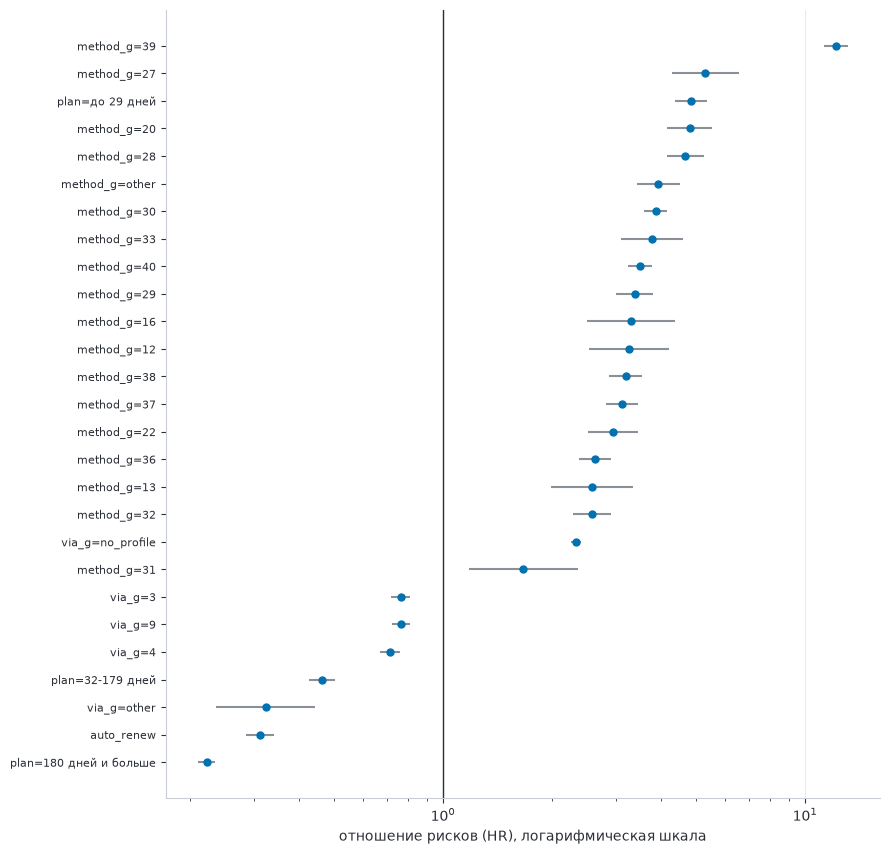

In [9]:
hr_plot = hr.sort_values("HR")
fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(hr_plot))))
y = np.arange(len(hr_plot))
ax.hlines(y, hr_plot["HR нижняя 95%"], hr_plot["HR верхняя 95%"], color=GRAY, lw=1.5)
ax.plot(hr_plot.HR, y, "o", color=BLUE, ms=5)
ax.axvline(1, color=INK, lw=1)
ax.set_yticks(y)
ax.set_yticklabels(hr_plot.index, fontsize=8)
ax.set_xlabel("отношение рисков (HR), логарифмическая шкала")
ax.set_xscale("log")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 6. Проверка допущения о постоянстве эффектов
Модель Кокса предполагает, что отношение рисков между группами не меняется с возрастом. Тест Шёнфельда проверяет это отдельно для каждого признака
на случайных 30 000 клиентов (на всей выборке тест слишком чувствителен: малые отклонения дают малые p). Малое p означает, что эффект признака
зависит от возраста, и единичное HR описывает его лишь в среднем. В таблице показаны 12 признаков с наименьшими p. Признаки, у которых в подвыборке меньше 20 событий, из теста исключаются: по ним оценка нестабильна.

In [10]:
sub = X.sample(min(30000, len(X)), random_state=42)
features = [c for c in sub.columns if c not in ("t", "event")]
few = [c for c in features if sub.loc[sub[c] == 1, "event"].sum() < 20]  # меньше 20 событий: оценка нестабильна
print("исключены из теста (в подвыборке меньше 20 событий):", few)
sub = sub.drop(columns=few)
cph_sub = CoxPHFitter().fit(sub, duration_col="t", event_col="event")
ph = proportional_hazard_test(cph_sub, sub, time_transform="rank").summary
ph.sort_values("p").head(12).round(4)

исключены из теста (в подвыборке меньше 20 событий): ['method_g=12', 'method_g=13', 'method_g=16', 'method_g=31', 'via_g=other']


,test_statistic,p,-log2(p)
plan=180 дней и больше,341.6044,0.0000,250.9535
plan=32-179 дней,66.8722,0.0000,51.6163
via_g=no_profile,54.6816,0.0000,42.6820
plan=до 29 дней,30.3959,0.0000,24.7587
via_g=3,20.4384,0.0000,17.3091
via_g=4,9.9489,0.0016,9.2792
method_g=other,9.7773,0.0018,9.1446
via_g=9,8.4853,0.0036,8.1257
method_g=39,6.7222,0.0095,6.7145
method_g=36,3.9569,0.0467,4.4210


## 7. Сверка с исторической LTV
Ожидаемое число активных месяцев в первые 12 по всей выборке: сколько месяцев из 12 клиент в среднем имеет непрерывную подписку.
В `03_ltv_history` доля активных к 12-му месяцу 74% (с возвратами); здесь учитывается только строго непрерывная подписка, поэтому показатель ниже.

In [11]:
s_all = kmf.survival_function_.iloc[:, 0]
pd.DataFrame({
    "показатель": ["активных месяцев из первых 12 (строго)", "S(12)"],
    "значение": [round(sum(surv_at(s_all, a) for a in range(12)), 2), round(surv_at(s_all, 12), 3)],
})

,показатель,значение
0,активных месяцев из первых 12 (строго),9.42
1,S(12),0.66


## Выводы
- **Общая кривая.** К 12-му месяцу строго непрерывная подписка сохраняется у 66,0% клиентов (95% ДИ 65,7–66,3%), к 18-му у 58,4%. Это согласуется с 64,2% из `02_cohorts`. Ожидаемое число активных месяцев в первые 12 составляет 9,42.
- **Автопродление** связано с удержанием сильнее прочих признаков: S(12) равно 0,78 против 0,47 без него, в модели Кокса HR 0,31 (риск ухода втрое ниже при прочих равных).
- **Длина тарифа.** При первой оплате на 180 дней и больше S(12) равно 0,86 (HR 0,22), на 30–31 день 0,64, на 32–179 дней 0,45, до 29 дней 0,05 (HR 4,8, но всего 399 клиентов). Высокое удержание длинных тарифов частично объясняется предоплатой: пока срок не истёк, клиент считается активным.
- **Способ оплаты** сильно различает клиентов: S(12) от 0,18 (метод 39, HR 12,2) до 0,87 (метод 22). Метод 41, на который приходится половина клиентов, даёт 0,82.
- **Профиль.** Простое сравнение не показывает различий (S(12) 0,658 с профилем и 0,669 без него), но в модели Кокса категория `no_profile` имеет HR 2,3 относительно базового способа регистрации (7): после учёта тарифа и способа оплаты клиенты без профиля уходят заметно быстрее.
- **Допущение пропорциональности нарушено** прежде всего у длинных тарифов (статистика Шёнфельда 342 и 67), у `no_profile` (55) и у тарифа до 29 дней (30). Для длинных тарифов причина понятна: риск ухода мал до конца предоплаченного срока и затем резко растёт. Поэтому HR для этих признаков следует читать как средние за весь период, а сравнение групп опирать на кривые Каплана–Мейера.
- **Ограничения.** Различия между сегментами это наблюдательные связи, а не причинные эффекты. «Активность» определяется по сроку действия подписки, а не по поведению клиента. Расчёт сделан на 15% клиентов; доверительные интервалы для малых категорий (меньше 500 клиентов) широки.
